# Исследование исторических котировок фьючерсов на нефть WTI (CL)

## 1. Цель исследования

Данное исследование выполняется в рамках проекта **«Предсказание движения цен на фьючерсы на основе текстовых данных»**.

Основная цель найти данные для обучения будующих моделей. 

В качестве исследуемого инструмента выбран **CL (Crude Oil Futures)** — биржевой фьючерсный контракт на нефть WTI, торгуемый на NYMEX (CME Group).

**Горизонт прогнозирования:** один торговый день.

Изучаем исходные рыночные данные, проверить их качество и определить правила их дальнейшего использования.

## 2. Источник данных

Для первоначального исследования используется Yahoo Finance через Python-библиотеку `yfinance`.

- Тикер: `CL=F`.
- Частота наблюдений: дневная (`1d`).
- Период: с 1 января 2016 года по 30 сентября 2026 года включительно.
- Количество полученных наблюдений: 2 701.
- Формат: OHLCV — цены открытия, максимума, минимума, закрытия и объём торгов.

`CL=F` представляет собой исторический ряд котировок фьючерса WTI, предоставляемый Yahoo Finance. Правила выбора активного контракта и перехода между контрактами требуют дополнительной проверки.
CL — это не один фьючерс, существующий десять лет. Это целое семейство контрактов, каждый из которых имеет собственную цену и дату окончания торгов.

Yahoo Finance не является официальным источником биржевых расчётных данных CME, поэтому важно сравнить результаты данных полученный от Yahoo Finance с реальными данными

## Природа контрактов
Например, CLZ26 расшифровывается так:
- CL — фьючерс на нефть WTI;
- Z — декабрь;
- 26 — 2026 год.


Если ты покупаешь CLZ26, то покупаешь именно декабрьский контракт. Его цена может измениться завтра, послезавтра и через неделю.
При этом цена январского CLF27 может изменяться иначе.
И это нормально: разные контракты — разные рыночные инструменты, хотя базовый товар у них один.




In [36]:
import yfinance as yf

# Фьючерс на нефть WTI
ticker = "CL=F"


df = yf.download(
    ticker,
    start="2016-01-01",
    end="2026-10-18",
    interval="1d",
    auto_adjust=False,
    progress=False,
    threads=False,
)

In [37]:
if df.empty:
    print("Данные не получены. Нужно проверить доступность API.")
else:
    print("Количество наблюдений:", len(df))
    print("Первая дата:", df.index.min())
    print("Последняя дата:", df.index.max())

    print("\nПервые 5 строк:")
    print(df.head())

    print("\nПоследние 5 строк:")
    print(df.tail())

Количество наблюдений: 2713
Первая дата: 2016-01-04 00:00:00
Последняя дата: 2026-10-16 00:00:00

Первые 5 строк:
Price       Adj Close      Close       High        Low       Open  Volume
Ticker           CL=F       CL=F       CL=F       CL=F       CL=F    CL=F
Date                                                                     
2016-01-04  36.759998  36.759998  38.389999  36.330002  37.599998  431985
2016-01-05  35.970001  35.970001  37.099998  35.740002  36.900002  410131
2016-01-06  33.970001  33.970001  36.389999  33.770000  36.180000  563811
2016-01-07  33.270000  33.270000  34.259998  32.099998  34.090000  617409
2016-01-08  33.160000  33.160000  34.340000  32.639999  33.299999  596496

Последние 5 строк:
Price        Adj Close       Close        High        Low       Open  Volume
Ticker            CL=F        CL=F        CL=F       CL=F       CL=F    CL=F
Date                                                                        
2026-10-12   93.739998   93.739998   94.360

Всего 2701 наблюдений

Проверяем целостность данных

In [38]:
print("\nПропуски:")
print(df.isna().sum())

print("\nСтатистика Close:")
print(df["Close"].describe())


print("\nМинимальная цена:")
print(df["Close"].idxmin(), df["Close"].min())

print("\nМаксимальная цена:")
print(df["Close"].idxmax(), df["Close"].max())

# Исследуем апрель 2020
print("\nАпрель 2020:")
print(df.loc["2020-04-15":"2020-04-24",
             ["Open", "High", "Low", "Close", "Volume"]])


Пропуски:
Price      Ticker
Adj Close  CL=F      0
Close      CL=F      0
High       CL=F      0
Low        CL=F      0
Open       CL=F      0
Volume     CL=F      0
dtype: int64

Статистика Close:
Ticker         CL=F
count   2713.000000
mean      65.123093
std       18.121361
min      -37.630001
25%       52.330002
50%       64.900002
75%       76.599998
max      123.699997

Минимальная цена:
Ticker
CL=F   2020-04-20
dtype: datetime64[s] Ticker
CL=F   -37.630001
dtype: float64

Максимальная цена:
Ticker
CL=F   2022-03-08
dtype: datetime64[s] Ticker
CL=F    123.699997
dtype: float64

Апрель 2020:
Price            Open       High        Low      Close   Volume
Ticker           CL=F       CL=F       CL=F       CL=F     CL=F
Date                                                           
2020-04-15  20.719999  20.889999  19.200001  19.870001   544797
2020-04-16  20.150000  20.530001  19.420000  19.870001   350942
2020-04-17  20.000000  20.219999  17.309999  18.270000   240628
2020-04-20 

Минимальная цена на фьючерсы CL (фьючерсы на нефть Light Sweet Crude Oil) в 2020 году 20-ого апреля составила −37,63 доллара за баррель

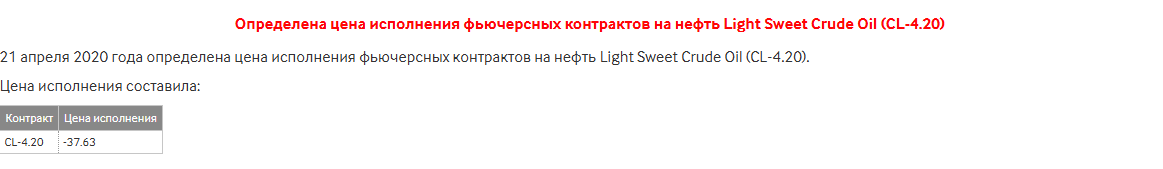

Что подвтерждает наша таблица.

In [39]:
df = df[
    ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
].copy()

df.index.name = "Date"

print(df.info())
print("\nДубликаты дат:", df.index.duplicated().sum())

print(
    "\nClose и Adj Close совпадают:",
    df["Close"].equals(df["Adj Close"])
)

<class 'pandas.DataFrame'>
DatetimeIndex: 2713 entries, 2016-01-04 to 2026-10-16
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Open, CL=F)       2713 non-null   float64
 1   (High, CL=F)       2713 non-null   float64
 2   (Low, CL=F)        2713 non-null   float64
 3   (Close, CL=F)      2713 non-null   float64
 4   (Adj Close, CL=F)  2713 non-null   float64
 5   (Volume, CL=F)     2713 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 212.9 KB
None

Дубликаты дат: 0

Close и Adj Close совпадают: True


Построим график цен по датам, дневном таймфрейме(мы и выгрузили только дневыне :) )

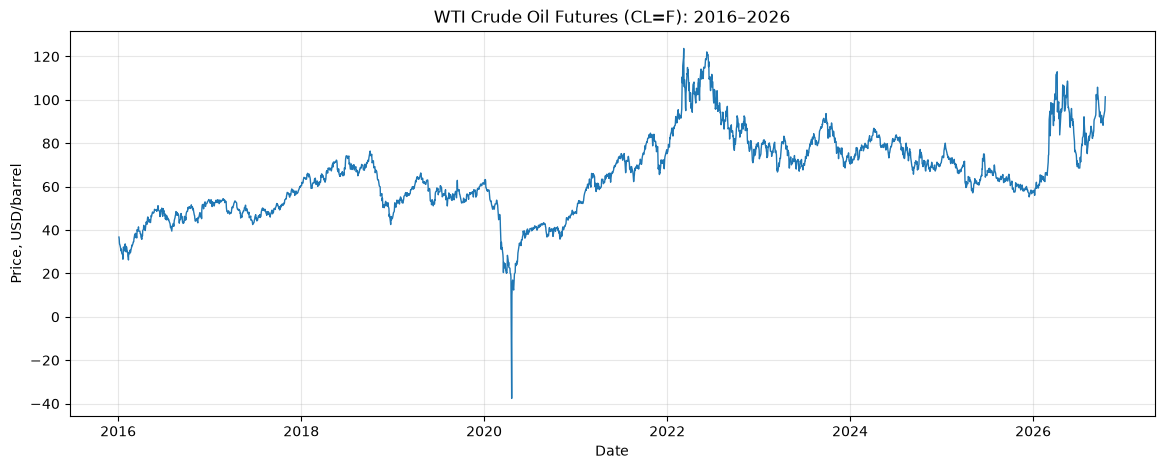

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df.index, df["Close"], linewidth=1)

ax.set_title("WTI Crude Oil Futures (CL=F): 2016–2026")
ax.set_xlabel("Date")
ax.set_ylabel("Price, USD/barrel")
ax.grid(alpha=0.3)

plt.show()

Для сравнения вот график с Tradingview


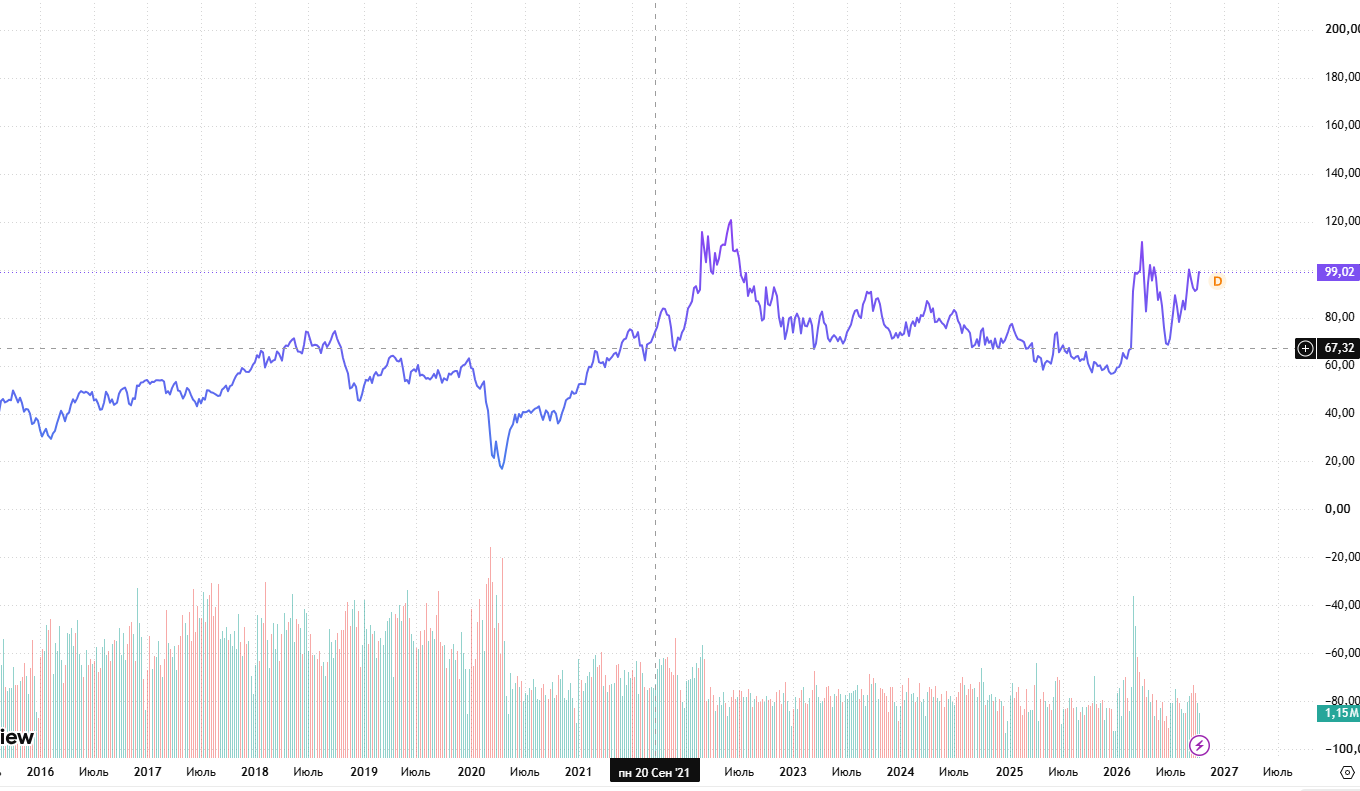


Графики различны потому, отображение идет на основе определенного контракта


Теперь нужно выяснить как происходит  rollover(переход между контрактами) в Yahoo Finance. Для  этого скачаем два контракта и изучим их.

Теперь попробуем скачать два отдельных контракта:
- CLX26.NYM - ноябрьский CL 2026 года.
- CLZ26.NYM - декабрьский CL 2026 года.
- CLF27.NYM - Январский CL 2026 года.


In [46]:
import yfinance as yf
import pandas as pd

# Параметры исследования
symbols = [
    "CLV26.NYM",  # Октябрь
    "CLX26.NYM",  # Ноябрь
    "CLZ26.NYM",  # Декабрь
    "CLF27.NYM"   # Январь
]

start_date = "2026-08-01"
end_date = "2026-10-18"

contracts = {}

for symbol in symbols:
    data = yf.download(
        symbol,
        start=start_date,
        end=end_date,
        interval="1d",
        auto_adjust=False,
        progress=False,
        threads=False
    )

    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.get_level_values(0)

    contracts[symbol] = data

    print(f"{symbol}: {len(data)} строк")

    if not data.empty:
        print(data[["Close", "Volume"]].head(3))

$CLV26.NYM: possibly delisted; no timezone found

1 Failed download:
['CLV26.NYM']: possibly delisted; no timezone found


CLV26.NYM: 0 строк
CLX26.NYM: 54 строк
Price           Close  Volume
Date                         
2026-08-03  75.680000   91911
2026-08-04  73.150002  140675
2026-08-05  72.940002  122193
CLZ26.NYM: 54 строк
Price           Close  Volume
Date                         
2026-08-03  73.940002   97431
2026-08-04  72.029999  152022
2026-08-05  71.870003  126422
CLF27.NYM: 54 строк
Price           Close  Volume
Date                         
2026-08-03  72.779999   41139
2026-08-04  71.209999   54310
2026-08-05  71.040001   51341


Сравниваем с CL-F

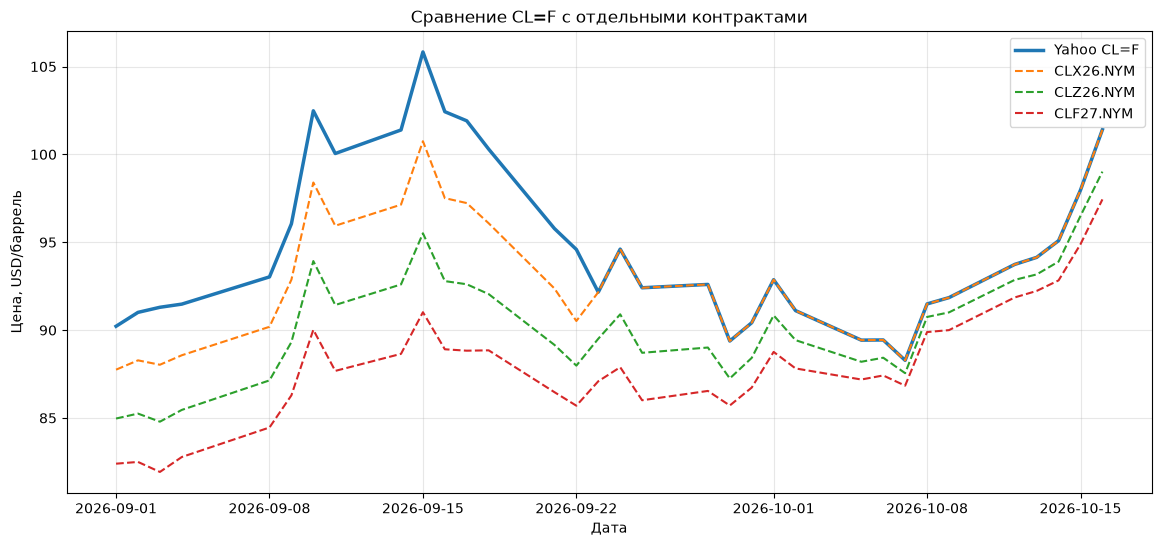

In [43]:


plt.figure(figsize=(14, 6))

plt.plot(
    df.loc["2026-09-01":"2026-10-18"].index,
    df.loc["2026-09-01":"2026-10-18", "Close"],
    label="Yahoo CL=F",
    linewidth=2.5
)

for symbol, data in contracts.items():
    if not data.empty:
        plt.plot(
            data.index,
            data["Close"],
            label=symbol,
            linestyle="--"
        )

plt.title("Сравнение CL=F с отдельными контрактами")
plt.xlabel("Дата")
plt.ylabel("Цена, USD/баррель")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Примерно 23 сентября Yahoo переключил CL=F на ноябрьский контракт.
До переключения Yahoo, вероятно, отображал октябрьский контракт CLV26.NYM.

In [48]:
ticker = yf.Ticker("CLV26.NYM")

print("История:")
print(ticker.history(period="max").shape)

print("\nИнформация:")
try:
    print(ticker.info.get("shortName"))
except Exception as e:
    print(type(e).__name__, str(e))

$CLV26.NYM: possibly delisted; no timezone found


История:
(0, 6)

Информация:


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CLV26.NYM"}}}


None


Судя по всему yahoo не предоставляет информацию по законченным контрактам

До переключения Yahoo отображает другой контракт (предположительно октябрьский).



После переключения — ноябрьский.



В момент переключения может появиться ценовой разрыв, который исказит доходность.

In [53]:
import pandas as pd

# Исправляем основной непрерывный ряд
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Исправляем все отдельные контракты
for symbol, data in contracts.items():
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.get_level_values(0)

    contracts[symbol] = data

In [55]:
import numpy as np

comparison = pd.DataFrame({
    "CL_continuous": df["Close"],
    "CL_november": contracts["CLX26.NYM"]["Close"]
}).dropna()

comparison["difference"] = (
    comparison["CL_continuous"] - comparison["CL_november"]
)

comparison["matches_november"] = np.isclose(
    comparison["difference"],
    0,
    atol=0.01
)

print(
    comparison.loc["2026-09-15":"2026-10-05"].round(3)
)

            CL_continuous  CL_november  difference  matches_november
Date                                                                
2026-09-15         105.83       100.75        5.08             False
2026-09-16         102.43        97.51        4.92             False
2026-09-17         101.91        97.23        4.68             False
2026-09-18         100.30        96.08        4.22             False
2026-09-21          95.78        92.37        3.41             False
2026-09-22          94.59        90.52        4.07             False
2026-09-23          92.16        92.16        0.00              True
2026-09-24          94.61        94.61        0.00              True
2026-09-25          92.41        92.41        0.00              True
2026-09-28          92.60        92.60        0.00              True
2026-09-29          89.38        89.38        0.00              True
2026-09-30          90.42        90.42        0.00              True
2026-10-01          92.87        9

22-ого числа CL-F отображал данные одного контрактка, затем другого.

CL-F отображает, что произошло падение, хотя сам ноябрьский контракт вырос.
